# 04 · Fuzzy C-Means, KMeans и GMM без меток исхода
## Кратко
По validation silhouette без меток выбрано кластеров: **FCM: 2, GMM: 2, KMeans: 2**. FCM на test: ARI **0.0741**, NMI **0.1215**; доли pathologic **6.9% / 9.4%** при общем уровне 8.2%. Bootstrap-интервалы обогащения **патологией** всех кластеров включают 1; отдельные патологические группы не подтверждены.

При этом доля **suspect** у FCM различается: 1.3%–27.2%. Это исследовательская связь с подозрительными паттернами; соответствующие групповые интервалы показаны отдельно. Геометрическая разделимость не равна выделению всех трёх уровней риска. Метки не использованы в fit или выборе конфигурации.

## Контекст и методы
Нелинейный преобразователь заново fit на train; индикаторы наличия редких событий удалены из расстояния, чтобы не считать их повторно. Числовые признаки стандартизованы; one-hot `Tendency` имеет единичное расстояние при смене категории. PCA сохраняет 90% обучающей дисперсии. Сетки: k=2..6; FCM m=1.5/2/2.5, 5 начальных состояний; KMeans n_init=20; GMM diag/full, n_init=5. Разделимость выбирается по silhouette validation, а не по близости к меткам.

### Ключевые допущения
Расстояния и PCA — модельные предположения; геометрический кластер может отражать тип сигнала, а не экспертный класс. В FCM проверяются сходимость, FPC, энтропия и устойчивость инициализаций; центры могут сближаться в многомерных данных. ARI/NMI и состав кластеров — описательные внешние проверки. Bootstrap по файлам учитывает зависимость сегментов; интервалы малых кластеров особенно широки.

In [3]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.training.ctg_experiments import OUT, MODELS, load_data, FAMILIES, CTG_FEATURES
sns.set_theme(style='whitegrid', palette=['#245b87', '#c47c2d', '#80659e'])
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
data, fingerprint = load_data()

## Обучение и выбор без меток

In [5]:
from src.training.ctg_clustering import run_clustering
cluster_grid, association, cluster_summary = run_clustering()
display(cluster_grid.sort_values(['algorithm','validation_silhouette'],ascending=[True,False]).round(4))

FCM: full unsupervised grid complete
KMeans: full unsupervised grid complete
GMM: full unsupervised grid complete


,key,algorithm,k,variant,train_silhouette,validation_silhouette,minimum_train_fraction,minimum_validation_fraction,converged,fpc,initialization_ari,minimum_center_distance,bic,chosen
0,FCM_2_1.5,FCM,2,1.5,0.1986,0.2600,0.4904,0.4457,True,0.6897,0.9978,3.2577,NaN,True
1,FCM_2_2.0,FCM,2,2.0,0.1973,0.2578,0.4993,0.4604,True,0.5400,0.9934,2.0885,NaN,False
2,FCM_2_2.5,FCM,2,2.5,0.1967,0.2563,0.4941,0.4663,True,0.5002,1.0000,0.1862,NaN,False
9,FCM_5_1.5,FCM,5,1.5,0.1870,0.2042,0.0691,0.0909,True,0.5080,0.9961,2.4451,NaN,False
3,FCM_3_1.5,FCM,3,1.5,0.1616,0.2030,0.2934,0.2815,True,0.5636,0.3354,2.4418,NaN,False
12,FCM_6_1.5,FCM,6,1.5,0.1685,0.1848,0.0610,0.0792,True,0.4594,0.9973,1.9244,NaN,False
6,FCM_4_1.5,FCM,4,1.5,0.1843,0.1795,0.1743,0.1935,True,0.5367,0.9995,2.8602,NaN,False
4,FCM_3_2.0,FCM,3,2.0,0.1486,0.1550,0.2449,0.1144,True,0.3719,0.6569,0.0478,NaN,False
7,FCM_4_2.0,FCM,4,2.0,0.0792,0.1199,0.0324,0.0117,True,0.2841,0.9979,0.0430,NaN,False
14,FCM_6_2.5,FCM,6,2.5,-0.0274,0.1111,0.0007,0.0000,True,0.1685,0.9768,0.0058,NaN,False


## Результаты · связь с экспертной разметкой после фиксации

Интервалы для suspect и abnormal=NSP>1 добавлены после просмотра таблицы состава как исследовательское уточнение. Число кластеров, параметры и обучение остались зафиксированными; эти интервалы не являются отдельным подтверждающим исследованием.

In [7]:
display(association.round(4))
display(cluster_summary[['algorithm','cluster','segments','source_files','path_fraction','enrichment','enrichment_low','enrichment_high']].round(4))
display(cluster_summary[['algorithm','cluster','suspect_fraction','suspect_enrichment','suspect_enrichment_low','suspect_enrichment_high','abnormal_fraction','abnormal_enrichment','abnormal_enrichment_low','abnormal_enrichment_high']].round(4))
print('Интервалы обогащения получены bootstrap по исходным файлам. Деление на малую исходную частоту повышает шум.')

Интервалы обогащения получены bootstrap по исходным файлам. Деление на малую исходную частоту повышает шум.


,algorithm,split,k,ari,nmi,silhouette,mean_membership_entropy
0,FCM,test,2,0.0741,0.1215,0.2355,0.6599
1,FCM,train,2,0.0374,0.0902,0.1986,0.6858
2,FCM,validation,2,0.0138,0.0952,0.2600,0.6382
3,GMM,test,2,-0.0024,0.0535,0.1994,0.0359
4,GMM,train,2,0.0041,0.0393,0.1675,0.0251
5,GMM,validation,2,-0.0005,0.0210,0.1861,0.0424
6,KMeans,test,2,0.0913,0.1294,0.2370,0.0000
7,KMeans,train,2,0.0474,0.0950,0.1968,0.0000
8,KMeans,validation,2,0.0244,0.1008,0.2582,0.0000


,algorithm,cluster,segments,source_files,path_fraction,enrichment,enrichment_low,enrichment_high
0,FCM,0,202,47,0.0693,0.8416,0.2220,1.9247
1,FCM,1,223,41,0.0942,1.1435,0.0000,1.6431
2,GMM,0,248,55,0.0565,0.6855,0.1938,1.5472
3,GMM,1,177,40,0.1186,1.4407,0.0000,2.0883
4,KMeans,0,230,42,0.0913,1.1087,0.0000,1.6072
5,KMeans,1,195,45,0.0718,0.8718,0.2266,2.0042


,algorithm,cluster,suspect_fraction,suspect_enrichment,suspect_enrichment_low,suspect_enrichment_high,abnormal_fraction,abnormal_enrichment,abnormal_enrichment_low,abnormal_enrichment_high
0,FCM,0,0.2723,1.9951,1.5898,2.7023,0.3416,1.5610,1.1138,2.0758
1,FCM,1,0.0135,0.0986,0.0000,0.2306,0.1076,0.4918,0.0403,0.8896
2,GMM,0,0.2056,1.5069,1.2323,1.8971,0.2621,1.1978,0.8600,1.5168
3,GMM,1,0.0395,0.2898,0.0787,0.6000,0.1582,0.7229,0.1859,1.1870
4,KMeans,0,0.0130,0.0956,0.0000,0.2225,0.1043,0.4769,0.0387,0.8711
5,KMeans,1,0.2821,2.0668,1.6286,2.8370,0.3538,1.6170,1.1430,2.1730


### Состав кластеров на test

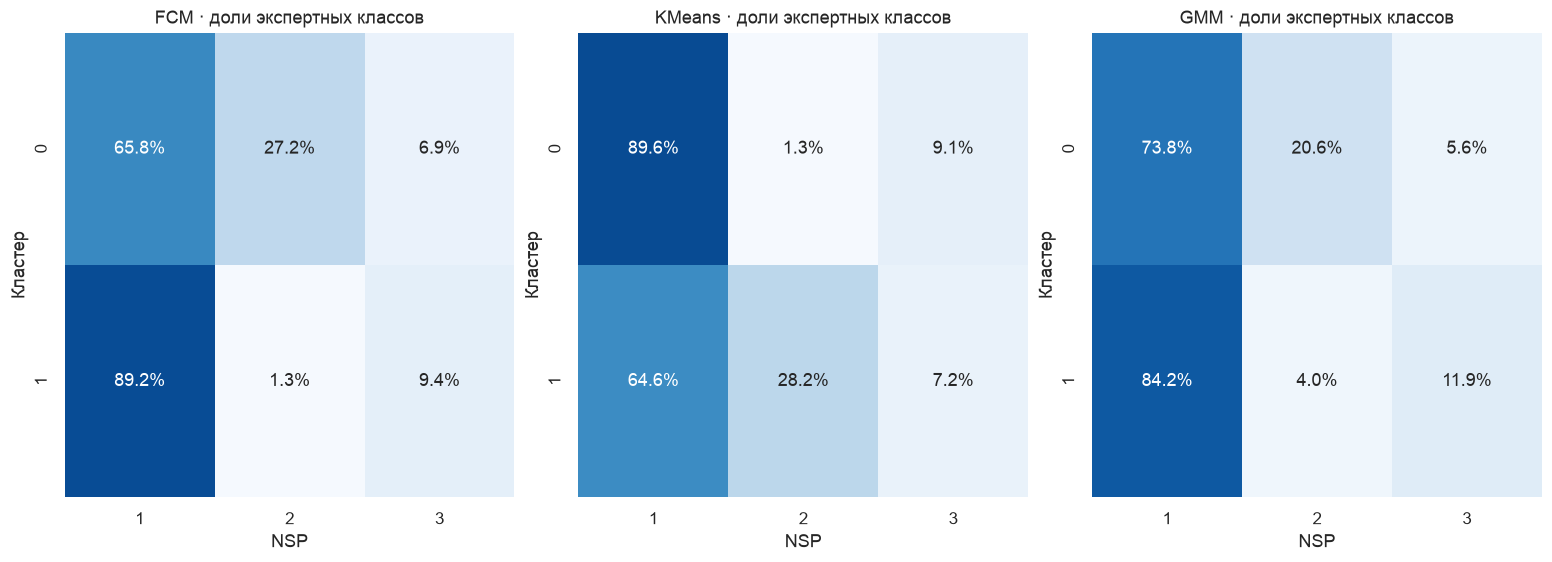

In [9]:
assignment = pd.read_parquet(OUT/'cluster_assignments.parquet')
fig,axes=plt.subplots(1,3,figsize=(14,5),constrained_layout=True)
for ax,algorithm in zip(axes,['FCM','KMeans','GMM']):
    part=assignment[(assignment.algorithm==algorithm)&(assignment.split=='test')]
    composition=pd.crosstab(part.cluster,part.NSP,normalize='index').reindex(columns=[1,2,3],fill_value=0)
    sns.heatmap(composition,annot=True,fmt='.1%',cmap='Blues',vmin=0,vmax=1,ax=ax,cbar=False)
    ax.set(title=f'{algorithm} · доли экспертных классов',xlabel='NSP',ylabel='Кластер')
plt.show()

### Геометрия и неоднозначность FCM

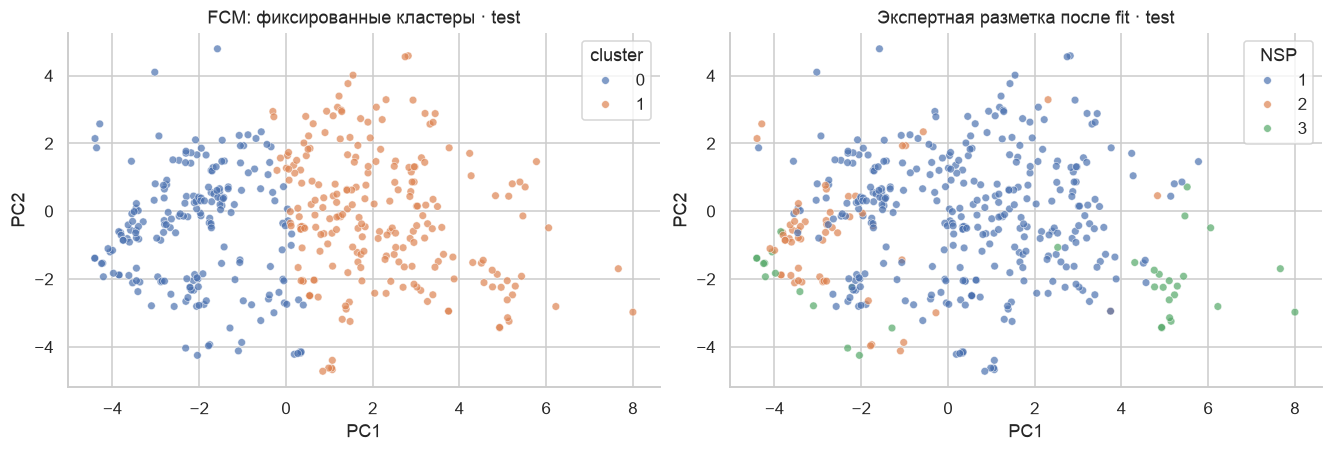

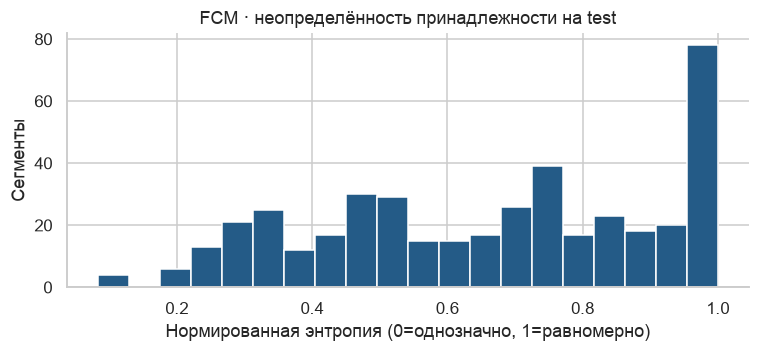

In [11]:
coordinates=pd.read_parquet(OUT/'cluster_projection.parquet')
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,column,title in [(axes[0],'cluster','FCM: фиксированные кластеры'),(axes[1],'NSP','Экспертная разметка после fit')]:
    sns.scatterplot(data=coordinates,x='PC1',y='PC2',hue=column,palette='deep',s=25,alpha=.7,ax=ax)
    ax.set_title(title+' · test')
plt.show()
fcm=assignment[(assignment.algorithm=='FCM')&(assignment.split=='test')]
fig,ax=plt.subplots(figsize=(8,3))
ax.hist(fcm.membership_entropy,bins=20,color='#245b87')
ax.set(title='FCM · неопределённость принадлежности на test',xlabel='Нормированная энтропия (0=однозначно, 1=равномерно)',ylabel='Сегменты')
plt.show()

## Выводы
Сначала оцените silhouette и устойчивость, затем ARI/NMI и обогащение. Даже высокая доля pathologic в одном кластере не делает его самостоятельным диагнозом; связь может не переноситься на другой источник. FCM-membership описывает близость к центрам и не является вероятностью патологии. Сравнение трёх алгоритмов и нескольких кластеров исследовательское, без подтверждающих p-value и без выбора конфигурации по test-меткам.